# 3 · Trust, but verify: when the frame itself is wrong

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/agent-engineering-studio/dpc-radar/blob/main/notebooks/03_trust_but_verify.ipynb)

Open data is a gift, not a guarantee. In October 2026 some `CUM24` frames arrived with a
smooth «bell» of up to **7,348 mm** over Abruzzo: more rain in a day than the rainiest place
in Italy gets in two years. It was not rain. It was a fault in the file.

A program that believes such a frame raises a false flood alarm. This notebook shows the fault
and the check `dpc-radar` uses to catch it. It runs **offline**: the frames are saved in the
repository, so it will work even after the DPC deletes the originals.

In [1]:
# On Colab (or any fresh environment) this installs the library; at home it does nothing.
import importlib.util

if importlib.util.find_spec("dpc_radar") is None:
    %pip install -q "dpc-radar[bulletins]" matplotlib

In [2]:
# Drawing helpers: a rain map in the colours of the README. Skip on a first read.
import json
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.transform import array_bounds
from rasterio.warp import Resampling, calculate_default_transform, reproject

DATA = Path("data")  # downloads are kept here, so a second run is fast
DATA.mkdir(exist_ok=True)
BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
LAND, BORDER, UNMEASURED = "#ecebe6", "#6f6e69", "#bdbcb6"
ITALY = (6.0, 36.3, 19.0, 47.3)  # west, south, east, north
CREDIT = "Data © Dipartimento della Protezione Civile, CC BY-SA 4.0 · borders: Natural Earth"
BORDERS_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
    "geojson/ne_50m_admin_0_countries.geojson"
)


def borders():
    """The outline of every country, from Natural Earth (public domain)."""
    file = DATA / "countries.geojson"
    if not file.exists():
        file.write_bytes(httpx.get(BORDERS_URL, timeout=120, follow_redirects=True).content)
    rings = []
    for feature in json.loads(file.read_text())["features"]:
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        rings += [np.array(polygon[0]) for polygon in polygons]
    return rings


def lonlat(grid):
    """The pixels of a frame on a longitude/latitude grid, and its corners."""
    data, transform = grid.data, grid.transform
    if grid.crs.to_epsg() != 4326:  # SRI and SRT1 use a projection in metres
        h, w = data.shape
        bounds = array_bounds(h, w, transform)
        transform, w, h = calculate_default_transform(grid.crs, "EPSG:4326", w, h, *bounds)
        data = np.full((h, w), np.nan, dtype="float32")
        reproject(
            grid.data,
            data,
            src_transform=grid.transform,
            src_crs=grid.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.nearest,
        )
    west, south, east, north = array_bounds(*data.shape, transform)
    return data, (west, east, south, north)


def rain_map(grid, ax, levels, *, box=ITALY, title="", unit="mm"):
    """Draw one frame: blue where it rained, grey where the radar did not measure."""
    data, extent = lonlat(grid)
    cmap = ListedColormap(BLUE)
    cmap.set_under("none")  # less than the first level: show the land
    cmap.set_bad(UNMEASURED)  # NaN: not measured, which is not the same as dry
    norm = BoundaryNorm(levels, cmap.N, extend="max")
    ax.set_facecolor("white")
    for ring in borders():
        ax.fill(ring[:, 0], ring[:, 1], color=LAND, zorder=0)
        ax.plot(ring[:, 0], ring[:, 1], color=BORDER, linewidth=0.6, zorder=3)
    image = ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.3)  # a degree of longitude is shorter than one of latitude here
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)
    bar = plt.colorbar(image, ax=ax, shrink=0.6, pad=0.02, ticks=levels)
    bar.set_label(unit)
    ax.plot([], [], "s", color=UNMEASURED, label="not measured")
    ax.legend(loc="lower left", fontsize=8, frameon=False, handletextpad=0.2)
    return image

In [3]:
from datetime import UTC, datetime

from dpc_radar import RainGrid

FRAMES = Path("../benchmarks/frames")  # in the repository
FRAMES_URL = (
    "https://raw.githubusercontent.com/agent-engineering-studio/dpc-radar/main/benchmarks/frames"
)


def load(case, which, time):
    """One saved frame of a known case: "frame", or the "previous" one 30 minutes before."""
    local = FRAMES / case / f"{which}.tif"
    if local.exists():
        raw = local.read_bytes()
    else:  # on Colab: take it from GitHub
        raw = httpx.get(f"{FRAMES_URL}/{case}/{which}.tif", follow_redirects=True).content
    return RainGrid.from_geotiff(raw, "CUM24", time)


good = load("bell-2026-10-11T0930", "previous", datetime(2026, 10, 11, 9, 0, tzinfo=UTC))
bad = load("bell-2026-10-11T0930", "frame", datetime(2026, 10, 11, 9, 30, tzinfo=UTC))
print(f"09:00 frame: highest value {np.nanmax(good.data):8.0f} mm")
print(f"09:30 frame: highest value {np.nanmax(bad.data):8.0f} mm")

09:00 frame: highest value      236 mm
09:30 frame: highest value     7348 mm


## Look at it

Two frames of the same product, thirty minutes apart, over the same mountains.

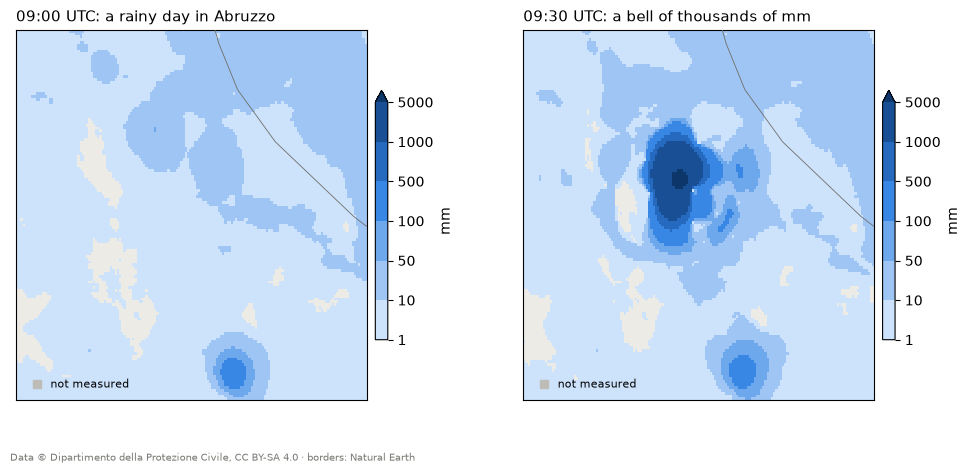

In [4]:
BOX = (13.0, 41.6, 14.6, 42.9)
levels = [1, 10, 50, 100, 500, 1000, 5000]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
rain_map(good, axes[0], levels, box=BOX, title="09:00 UTC: a rainy day in Abruzzo")
rain_map(bad, axes[1], levels, box=BOX, title="09:30 UTC: a bell of thousands of mm")
fig.text(0.12, 0.04, CREDIT, fontsize=7, color="#7a7974")
plt.show()

## The idea of the check

`CUM24` at 09:30 and `CUM24` at 09:00 cover almost the same 24 hours: they share 23 and a
half of them. So they can differ only by **half an hour of rain**. If a pixel changes by
hundreds of millimetres, one of the two frames is wrong.

Which one? Every fault seen so far **adds** rain. So:

- the frame jumped **up** → it is the faulty one: reject it, keep using the previous;
- the frame jumped **down** → the previous one was faulty: this one is fine.

`check` does exactly this. `max_step` is the largest believable change: 150 mm in half an
hour is far beyond any real storm.

In [5]:
result = bad.check(good, max_step=150.0)
print("verdict :", result.verdict)
print("pixels that jumped more than 150 mm :", f"{result.jumps:,}")
print("usable  :", result.usable)

verdict : rejected
pixels that jumped more than 150 mm : 960
usable  : False


## The frame after the bell

At 10:00 a clean frame arrives. Compared with the faulty 09:30 one it also «jumps»: down.
A naive rule would throw away the good frame too. `check` reads the sign and keeps it.

In [6]:
after = load("after-bell-2026-10-11T10", "frame", datetime(2026, 10, 11, 10, 0, tzinfo=UTC))
before = load("after-bell-2026-10-11T10", "previous", datetime(2026, 10, 11, 9, 30, tzinfo=UTC))

result = after.check(before, max_step=150.0)
print("verdict :", result.verdict)
print("usable  :", result.usable)
print(f"Gran Sasso: {result.grid.sample([(13.70, 42.39)])[0]:.1f} mm, kept")

verdict : previous_wrong
usable  : True
Gran Sasso: 8.5 mm, kept


## Why not simply delete the pixels that jump?

It is the first idea everybody has, and `dpc-radar` keeps it as `discard_inconsistent` to
compare. It removes the top of the bell, but not its **edges**, where the error is «only»
tens of millimetres: small enough to pass, large enough to look like a real storm.

In [7]:
edge = [(13.865, 42.285)]
truth = good.sample(edge)[0]

naive, removed = bad.discard_inconsistent(good, max_step=150.0)
checked = bad.check(good, max_step=150.0)
trusted = checked.grid or good  # rejected: keep using the previous frame

print(f"true rain at the edge of the bell        : {truth:5.1f} mm")
print(
    f"delete the jumping pixels ({removed:,} removed) : {naive.sample(edge)[0]:5.1f} mm  <- wrong"
)
print(f"reject the whole frame                    : {trusted.sample(edge)[0]:5.1f} mm")

true rain at the edge of the bell        :   9.1 mm
delete the jumping pixels (960 removed) :  87.7 mm  <- wrong
reject the whole frame                    :   9.1 mm


## It must not cry wolf

A check that rejects real storms is worse than no check. The frame of the Melito storm
(about 180 mm in a day, the subject of notebook 2) must pass untouched.

In [8]:
storm = load("melito-2026-10-11T00", "frame", datetime(2026, 10, 11, 0, 0, tzinfo=UTC))
earlier = load("melito-2026-10-11T00", "previous", datetime(2026, 10, 10, 23, 30, tzinfo=UTC))

result = storm.check(earlier, max_step=150.0)
print("verdict :", result.verdict)
print(f"Melito di Porto Salvo: {result.grid.sample([(15.78, 37.92)])[0]:.0f} mm, kept")

verdict : consistent
Melito di Porto Salvo: 180 mm, kept


## In your own program

```python
previous = None
async with RadarClient() as radar:
    frame = await radar.latest("CUM24")
    if previous is not None:
        result = frame.check(previous, max_step=150.0)
        frame = result.grid or previous   # rejected: stay on the last good frame
    previous = frame
```

## How good is the check?

It is measured, not promised. The repository keeps a small
[benchmark](https://github.com/agent-engineering-studio/dpc-radar/tree/main/benchmarks) of
real cases with a known answer: this rule passes **17 of 18** checks, against 8 of 18 for
«delete the pixels that jump». What it cannot see is a fault that **does not move** from one
frame to the next: the round spot at the bottom of both maps above is a suspect of that
kind. That is written down too, and it is the next thing to solve.

**Next:** [4 · Hourly rain from your own archive](04_hourly_rain_archive.ipynb).

*Radar data © Dipartimento della Protezione Civile, CC BY-SA 4.0.*